# Project summary
> Can EEG activity in a specific time window predict the participant’s perceived emotion, separately within each ambiguity level?


1. Decoding fear or happy with binary classification within each ambiguity level

2. Cross-decoding to test generalization of ambiguity level

    a. Training emotion classification using low ambiguity trials only

    b. Apply this trained model to high ambiguity trials.

    c. Evaluate the accuracy. If accuracy is still high, the emotion code is stable.


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

import mne
import numpy as np
import os
import re
import scipy.io as sio
from scipy.signal import welch
from collections import defaultdict, deque
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import balanced_accuracy_score
from sklearn.preprocessing import StandardScaler


from sklearn.pipeline import Pipeline
from mne.decoding import CSP
from sklearn.svm import SVC, LinearSVC
from mne.preprocessing import ICA
from sklearn.decomposition import PCA

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.base import clone
from mne.time_frequency import tfr_morlet
from sklearn.model_selection import RepeatedStratifiedKFold


`pip install pandas numpy scikit-learn matplotlib seaborn openpyxl`

`pip install mne pandas scikit-learn openpyxl matplotlib`

In [2]:
import pandas as pd
import numpy as np

path = "03 EEG Data and Code/FearHappyJudgment_Behavior and LPP.xlsx"

df = pd.read_excel(path).iloc[:, :5]

df.head()

,subID,codeL,vResp,RT,LPP
0,1,2,0,1143,1.747909
1,1,3,0,1233,5.892490
2,1,2,0,1195,4.262819
3,1,6,1,1115,2.531541
4,1,4,0,1214,-2.017248


`subID`: participant

`codeL`: morph level (1–7)

`vResp`: participant decision

`RT`: response time

`LPP`: EEG amplitude

# Check Behavior and LPP data
Morph level (1 happy → 7 fear)

- low ambiguity      : 1,7

- medium ambiguity   : 2,3,5,6

- high ambiguity     : 4

,subID,codeL,vResp,RT,LPP,ambiguity
0,1,2,0,1143,1.747909,medium
1,1,3,0,1233,5.892490,medium
2,1,2,0,1195,4.262819,medium
3,1,6,1,1115,2.531541,medium
4,1,4,0,1214,-2.017248,high


ambiguity
high       565
low       1137
medium    2301
dtype: int64

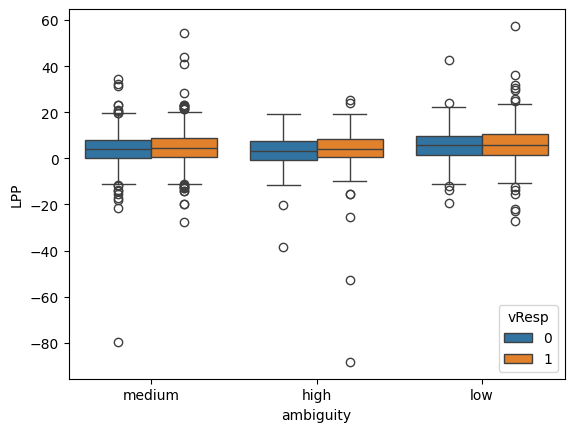

In [3]:
# Bin the codeL values into low, medium, and high ambiguity
# Check the distribution of codeL values
def ambiguity_bin(code):
    if code in [1,7]:
        return "low"
    if code in [2,3,5,6]:
        return "medium"
    if code == 4:
        return "high"

df["ambiguity"] = df["codeL"].apply(ambiguity_bin)
display(df.head())
display(df.groupby("ambiguity").size())

sns.boxplot(data=df, x="ambiguity", y="LPP", hue="vResp")
plt.show()

# Preprocessing
Use **perceived valence** from `vResp (fear=1, happy=0)` in behaviorData.mat instead of objective EEG-side valence.

E.g. EEG tags `B7(17)` are decoded as `codeI=1`(face ID) and `codeL=7` (face level), then matched to behavior trials by `codeI, codeL` using FIFO order.

All morph levels 1–7 are now included in training and evaluation.

### 1. Load EEG subject

In [4]:
eeg_path = "03 EEG Data and Code/MainTask_ShortEpoch"
# eeg_path = "03 EEG Data and Code/MainTask_LongEpoch"
behavior_mat_path = "02 Behavioral Data and Code/behaviorData.mat"

In [47]:
file = os.path.join(eeg_path, "sub1ar.set")
epochs = mne.io.read_epochs_eeglab(file)
epochs


Extracting parameters from /Users/grantsfolder/Desktop/COGS 189/COGS189_Face_emotion_EEG/03 EEG Data and Code/MainTask_ShortEpoch/sub1ar.set...
Not setting metadata
203 matching events found
No baseline correction applied
0 projection items activated
Ready.


<EpochsEEGLAB | 203 events (all good), -0.2 – 0.798 s (baseline off), ~25.6 MiB, data loaded,
 'B1(31)': 8
 'B2(32)': 9
 'B3(33)': 7
 'B5(45)': 8
 'B2(22)': 9
 'B6(46)': 7
 'B4(24)': 7
 'B7(37)': 8
 'B4(44)': 7
 'B5(35)': 6
 and 18 more events ...>

### 2. Extract Morph Levels
* vResp:  button press 1 happy; 2 fear.
* codeI: Face ID
* codeL: 7 (decreasing) fearful levels (1 happiest; 7 most fearful)

Goal output: y==0 happy, y==1 fear


In [48]:
# Parse EEG event labels to extract codeI (face ID) and codeL (morph level) per trial
# Example: B7(17) -> codeI=1, codeL=7

inv_event_id = {v: k for k, v in epochs.event_id.items()}
events = epochs.events[:, 2]
event_names = [inv_event_id[e] for e in events]

event_codeI = []
event_codeL = []

for name in event_names:
    m = re.search(r"\((\d+)(\d)\)", name)
    if m is None:
        raise ValueError(f"Cannot parse event name: {name}")
    code_i = int(m.group(1))
    code_l = int(m.group(2))
    event_codeI.append(code_i)
    event_codeL.append(code_l)

event_codeI = np.array(event_codeI)
morph_levels = np.array(event_codeL)

print("Unique morph levels in EEG:", np.unique(morph_levels, return_counts=True))
print("Unique face IDs in EEG:", np.unique(event_codeI, return_counts=True))

Unique morph levels in EEG: (array([1, 2, 3, 4, 5, 6, 7]), array([29, 32, 30, 28, 30, 24, 30]))
Unique face IDs in EEG: (array([1, 2, 3, 4]), array([51, 48, 51, 53]))


In [49]:
# Load perceived responses from behaviorData.mat and align to EEG events
mat = sio.loadmat(behavior_mat_path, struct_as_record=False, squeeze_me=True)
eeg_data = mat["eegData"]

# Get subject number from EEG filename: sub1ar.set -> 1
sub_match = re.search(r"sub(\d+)", os.path.basename(file))
if sub_match is None:
    raise ValueError(f"Could not infer subject ID from filename: {file}")
sub_id = int(sub_match.group(1))

sub_beh = eeg_data[sub_id - 1]  # matlab is 1-indexed; python is 0-indexed
beh_codeI = np.asarray(sub_beh.codeI).astype(int)
beh_codeL = np.asarray(sub_beh.codeL).astype(int)
beh_vResp = np.asarray(sub_beh.vResp).astype(int)

print(f"Subject {sub_id}: behavior trials = {len(beh_vResp)}, EEG trials = {len(morph_levels)}")

# Build FIFO queues for perceived responses keyed by (codeI, codeL)
resp_queue = defaultdict(deque)
for ci, cl, vr in zip(beh_codeI, beh_codeL, beh_vResp):
    resp_queue[(ci, cl)].append(vr)

# Match each EEG trial to perceived response using codeI + codeL
matched_vResp = []
missing = 0
for ci, cl in zip(event_codeI, morph_levels):
    key = (int(ci), int(cl))
    if len(resp_queue[key]) == 0:
        matched_vResp.append(np.nan)
        missing += 1
    else:
        matched_vResp.append(resp_queue[key].popleft())

matched_vResp = np.asarray(matched_vResp, dtype=float)
print(f"Matched EEG trials: {np.sum(~np.isnan(matched_vResp))}/{len(matched_vResp)}")
print(f"Unmatched EEG trials: {missing}")

Subject 1: behavior trials = 252, EEG trials = 203
Matched EEG trials: 203/203
Unmatched EEG trials: 0


### 3. Extract emotion and ambiguity labels

In [50]:
# Keep only trials that were successfully matched to behavior data
valid_mask = ~np.isnan(matched_vResp)

epochs = epochs[valid_mask]
event_codeI = event_codeI[valid_mask]
morph_levels = morph_levels[valid_mask]
matched_vResp = matched_vResp[valid_mask].astype(int)

# Perceived valence label from behavior
y = np.zeros(len(matched_vResp), dtype=int)
y[matched_vResp == 2] = 1

print("Final trial count:", len(y))
print("Label counts (0=happy, 1=fear):", np.unique(y, return_counts=True))

Final trial count: 203
Label counts (0=happy, 1=fear): (array([0, 1]), array([ 90, 113]))


In [51]:
def ambiguity_bin(code):
    if code in [1, 7]:
        return "low"
    elif code in [2, 3, 5, 6]:
        return "medium"
    elif code == 4:
        return "high"
    return "unknown"

ambiguity = np.array([ambiguity_bin(c) for c in morph_levels])
ambiguity_count = np.unique(ambiguity, return_counts=True)
[(str(ambiguity_count[0][i]) + ": " + str(ambiguity_count[1][i])) for i in range(3)]

['high: 28', 'low: 59', 'medium: 116']

# Exploratory analysis

In [52]:
epochs_filt = epochs.copy().filter(l_freq=0.1, h_freq=40.)
epochs_filt.apply_baseline((-0.2, 0))

Setting up band-pass filter from 0.1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.10
- Lower transition bandwidth: 0.10 Hz (-6 dB cutoff frequency: 0.05 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 16501 samples (33.002 s)



/var/folders/bj/p5l9vvcj21nfh__sngfwhp3h0000gn/T/ipykernel_31040/919858817.py:1: RuntimeWarning: filter_length (16501) is longer than the signal (500), distortion is likely. Reduce filter length or filter a longer signal.
  epochs_filt = epochs.copy().filter(l_freq=0.1, h_freq=40.)


Applying baseline correction (mode: mean)


<EpochsEEGLAB | 203 events (all good), -0.2 – 0.798 s (baseline -0.2 – 0 s), ~25.6 MiB, data loaded,
 'B1(31)': 8
 'B2(32)': 9
 'B3(33)': 7
 'B5(45)': 8
 'B2(22)': 9
 'B6(46)': 7
 'B4(24)': 7
 'B7(37)': 8
 'B4(44)': 7
 'B5(35)': 6
 and 18 more events ...>

## ERP comparison

| Component | Time | Location | Meaning |
|---|---|---|---|
| P1 | 80–120 ms | occipital | early visual |
| N170 | 140–200 ms | P7/P8 | face processing |
| LPP | 300–600 ms | centroparietal | emotional evaluation |

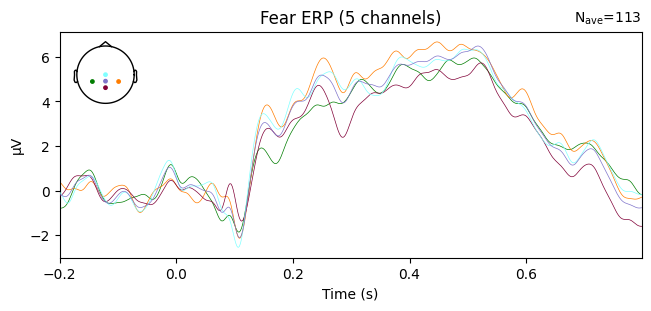

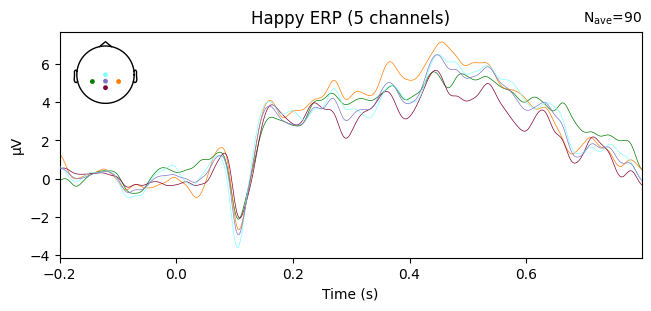

combining channels using "mean"
combining channels using "mean"


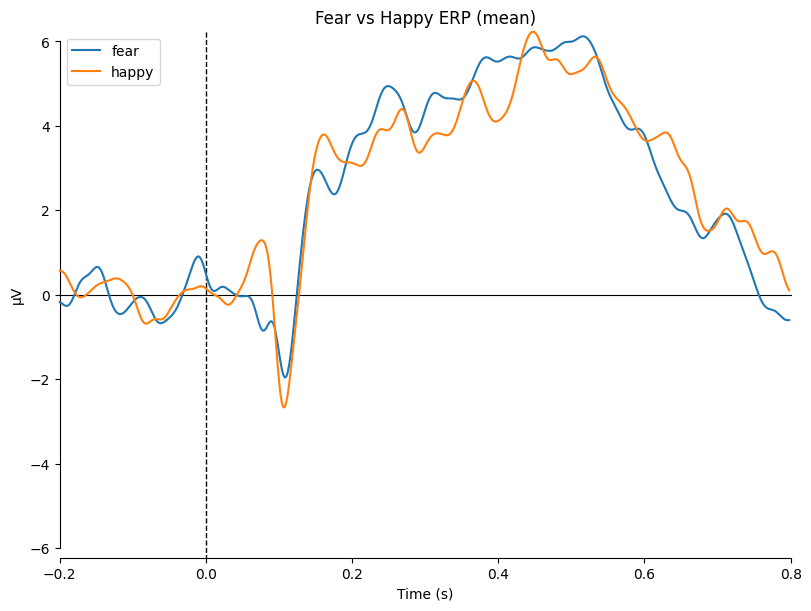

[<Figure size 800x600 with 1 Axes>]

In [76]:
# Separate conditions
epochs_fear = epochs_filt[y == 1]
epochs_happy = epochs_filt[y == 0]

# Compute evoked averages
evoked_fear = epochs_fear.average()
evoked_happy = epochs_happy.average()

# Plot ERP comparison
# picks = ['P7','P8','PZ','OZ','CZ']
picks = ['CP3','CP4','PZ','CZ','CPZ']

evoked_fear.plot(picks=picks, spatial_colors=True, titles="Fear ERP")
evoked_happy.plot(picks=picks, spatial_colors=True, titles="Happy ERP")

# Overlay comparison
mne.viz.plot_compare_evokeds(
    {"fear": evoked_fear, "happy": evoked_happy},
    picks=picks,
    combine="mean",
    title="Fear vs Happy ERP"
)

## Time–frequency analysis (STFT / Morlet)
### Difference spectrogram

| Band            | Interpretation           |
|-----------------|--------------------------|
| theta (4–7 Hz)  | emotion processing       |
| alpha (8–12 Hz) | attentional suppression  |
| beta (13–30 Hz) | cognitive evaluation     |

In [ ]:
from mne.time_frequency import tfr_morlet

freqs = np.arange(4, 40, 2)  # frequency bands
n_cycles = freqs / 2

power = tfr_morlet(
    epochs_filt,
    freqs=freqs,
    n_cycles=n_cycles,
    return_itc=False,
    average=False
)

power_fear = power[y == 1]
power_happy = power[y == 0]

avg_fear = power_fear.average()
avg_happy = power_happy.average()

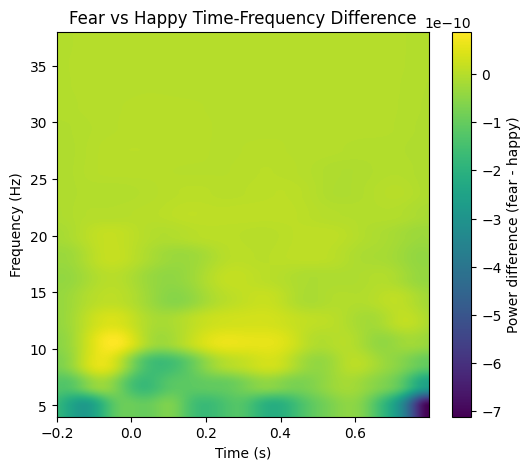

In [ ]:
diff = avg_fear.data - avg_happy.data

plt.figure(figsize=(6,5))

plt.imshow(
    diff.mean(axis=0),
    aspect="auto",
    origin="lower",
    extent=[epochs.times[0], epochs.times[-1], freqs[0], freqs[-1]]
)

plt.colorbar(label="Power difference (fear - happy)")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("Fear vs Happy Time-Frequency Difference")

plt.show()

# Average ERP

Subject 1: included (fear=113, happy=90)
Subject 2: included (fear=72, happy=130)
Subject 3: included (fear=93, happy=94)
Subject 4: included (fear=71, happy=119)
Subject 5: included (fear=88, happy=81)
Subject 6: included (fear=114, happy=92)
Subject 7: file not found, skipped
Subject 8: included (fear=83, happy=85)
Subject 9: included (fear=108, happy=119)
Subject 10: included (fear=64, happy=144)
Subject 11: included (fear=62, happy=140)
Subject 12: included (fear=51, happy=82)
Subject 13: included (fear=88, happy=132)
Subject 14: included (fear=100, happy=94)
Subject 15: included (fear=105, happy=86)
Subject 16: included (fear=82, happy=129)
Subject 17: included (fear=81, happy=154)
Subject 18: included (fear=121, happy=93)
Subject 19: included (fear=106, happy=121)
Subject 20: included (fear=107, happy=133)
Subject 21: included (fear=47, happy=38)
Subject 22: included (fear=78, happy=131)
Subject 23: included (fear=79, happy=75)
Included subjects for group plots: 22
Identifying co

/var/folders/bj/p5l9vvcj21nfh__sngfwhp3h0000gn/T/ipykernel_31040/3832778131.py:137: RuntimeWarning: Only 1 channel in "picks"; cannot combine by method "mean".
  mne.viz.plot_compare_evokeds(


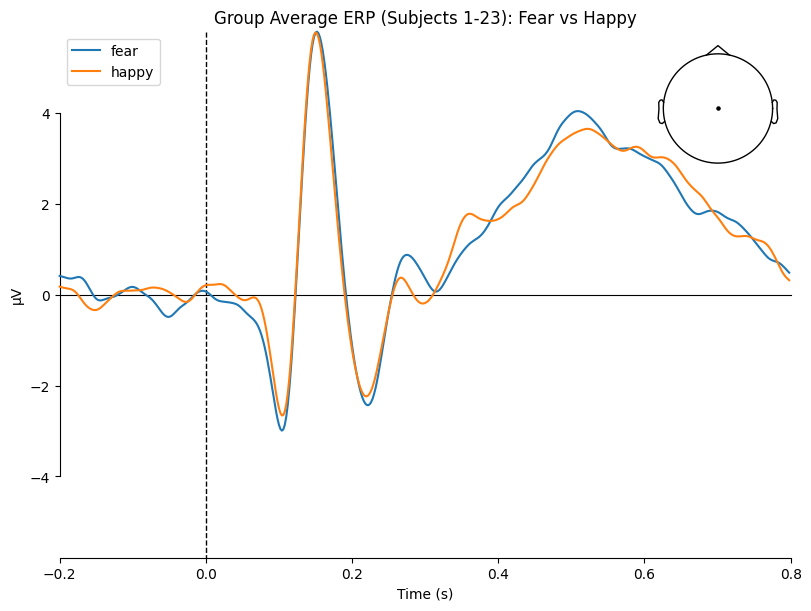

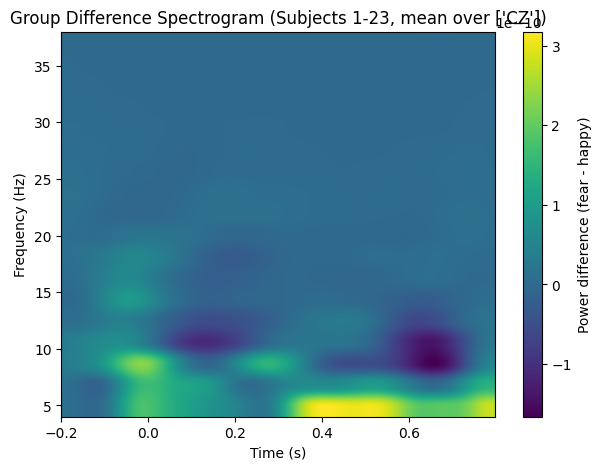

In [97]:
# Group average ERP + difference spectrogram (first 10 subjects)
from collections import defaultdict, deque

range_min = 1
range_max = 23
# group_picks = ['P7','P8','PZ','OZ','CZ']
# group_picks = ['CP3','CP4','PZ','CZ','CPZ']
group_picks = ['CZ']
subject_ids = range(range_min, range_max + 1)

# Use same frequency settings as exploratory TFR, define if not present
if 'freqs' not in globals():
    freqs = np.arange(4, 40, 2)
if 'n_cycles' not in globals():
    n_cycles = freqs / 2

mat = sio.loadmat(behavior_mat_path, struct_as_record=False, squeeze_me=True)
eeg_data = mat["eegData"]

evoked_fear_list = []
evoked_happy_list = []
tfr_diff_data_list = []
tfr_times = None

def _extract_codes_from_epochs(ep):
    inv_event_id = {v: k for k, v in ep.event_id.items()}
    events = ep.events[:, 2]
    event_names = [inv_event_id[e] for e in events]

    event_codeI_local = []
    morph_levels_local = []
    for name in event_names:
        m = re.search(r"\((\d+)(\d)\)", name)
        if m is None:
            raise ValueError(f"Cannot parse event name: {name}")
        event_codeI_local.append(int(m.group(1)))
        morph_levels_local.append(int(m.group(2)))

    return np.array(event_codeI_local), np.array(morph_levels_local)

for sub_id in subject_ids:
    file = os.path.join(eeg_path, f"sub{sub_id}ar.set")
    if not os.path.exists(file):
        print(f"Subject {sub_id}: file not found, skipped")
        continue

    try:
        epochs_sub = mne.io.read_epochs_eeglab(file, verbose=False)
    except Exception as e:
        print(f"Subject {sub_id}: load failed ({e}), skipped")
        continue

    event_codeI_sub, morph_levels_sub = _extract_codes_from_epochs(epochs_sub)

    sub_beh = eeg_data[sub_id - 1]
    beh_codeI = np.asarray(sub_beh.codeI).astype(int)
    beh_codeL = np.asarray(sub_beh.codeL).astype(int)
    beh_vResp = np.asarray(sub_beh.vResp).astype(int)

    resp_queue = defaultdict(deque)
    for ci, cl, vr in zip(beh_codeI, beh_codeL, beh_vResp):
        resp_queue[(ci, cl)].append(vr)

    matched_vResp = []
    for ci, cl in zip(event_codeI_sub, morph_levels_sub):
        key = (int(ci), int(cl))
        if len(resp_queue[key]) == 0:
            matched_vResp.append(np.nan)
        else:
            matched_vResp.append(resp_queue[key].popleft())

    matched_vResp = np.asarray(matched_vResp, dtype=float)
    valid_mask = ~np.isnan(matched_vResp)

    if valid_mask.sum() == 0:
        print(f"Subject {sub_id}: no matched trials, skipped")
        continue

    epochs_sub = epochs_sub[valid_mask]
    matched_vResp = matched_vResp[valid_mask].astype(int)

    y_sub = np.zeros(len(matched_vResp), dtype=int)
    y_sub[matched_vResp == 2] = 1  # fear=1, happy=0

    fear_mask = y_sub == 1
    happy_mask = y_sub == 0

    if fear_mask.sum() == 0 or happy_mask.sum() == 0:
        print(f"Subject {sub_id}: missing one class, skipped")
        continue

    # Use IIR filtering to avoid very long FIR kernels on short epochs
    epochs_sub = epochs_sub.copy().filter(
        l_freq=0.1,
        h_freq=40.,
        method='iir',
        iir_params={'order': 4, 'ftype': 'butter'},
        verbose=False
    )
    epochs_sub.apply_baseline((-0.2, 0), verbose=False)
    epochs_sub = epochs_sub.copy().pick(group_picks, verbose=False)

    evoked_fear_sub = epochs_sub[fear_mask].average()
    evoked_happy_sub = epochs_sub[happy_mask].average()
    evoked_fear_list.append(evoked_fear_sub)
    evoked_happy_list.append(evoked_happy_sub)

    # Replace legacy tfr_morlet() with the modern API
    tfr_fear_sub = epochs_sub[fear_mask].compute_tfr(
        method='morlet',
        freqs=freqs,
        n_cycles=n_cycles,
        return_itc=False,
        average=True,
        verbose=False
    )
    tfr_happy_sub = epochs_sub[happy_mask].compute_tfr(
        method='morlet',
        freqs=freqs,
        n_cycles=n_cycles,
        return_itc=False,
        average=True,
        verbose=False
    )

    tfr_diff_data_list.append(tfr_fear_sub.data - tfr_happy_sub.data)
    tfr_times = tfr_fear_sub.times

    print(f"Subject {sub_id}: included (fear={fear_mask.sum()}, happy={happy_mask.sum()})")

print(f"Included subjects for group plots: {len(evoked_fear_list)}")

if len(evoked_fear_list) > 0:
    group_evoked_fear = mne.grand_average(evoked_fear_list)
    group_evoked_happy = mne.grand_average(evoked_happy_list)

    mne.viz.plot_compare_evokeds(
        {"fear": group_evoked_fear, "happy": group_evoked_happy},
        picks=group_picks,
        combine='mean',
        title=f"Group Average ERP (Subjects {range_min}-{range_max}): Fear vs Happy"
    )

if len(tfr_diff_data_list) > 0:
    group_tfr_diff = np.mean(np.stack(tfr_diff_data_list, axis=0), axis=0)  # ch x f x t
    group_tfr_diff_mean_ch = group_tfr_diff.mean(axis=0)  # f x t

    plt.figure(figsize=(7, 5))
    plt.imshow(
        group_tfr_diff_mean_ch,
        aspect='auto',
        origin='lower',
        extent=[tfr_times[0], tfr_times[-1], freqs[0], freqs[-1]]
    )
    plt.colorbar(label='Power difference (fear - happy)')
    plt.xlabel('Time (s)')
    plt.ylabel('Frequency (Hz)')
    plt.title(f'Group Difference Spectrogram (Subjects {range_min}-{range_max}, mean over {group_picks})')
    plt.show()

Subject 1: processed
Subject 2: processed
Subject 3: processed
Subject 4: processed
Subject 5: processed
Subject 6: processed
Subject 7: file not found, skipped
Subject 8: processed
Subject 9: processed
Subject 10: processed
Subject 11: processed
Subject 12: processed
Subject 13: processed
Subject 14: processed
Subject 15: processed
Subject 16: processed
Subject 17: processed
Subject 18: processed
Subject 19: processed
Subject 20: processed
Subject 21: processed
Subject 22: processed
Subject 23: processed

Plotting ERP comparisons by ambiguity level
Identifying common channels ...
Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


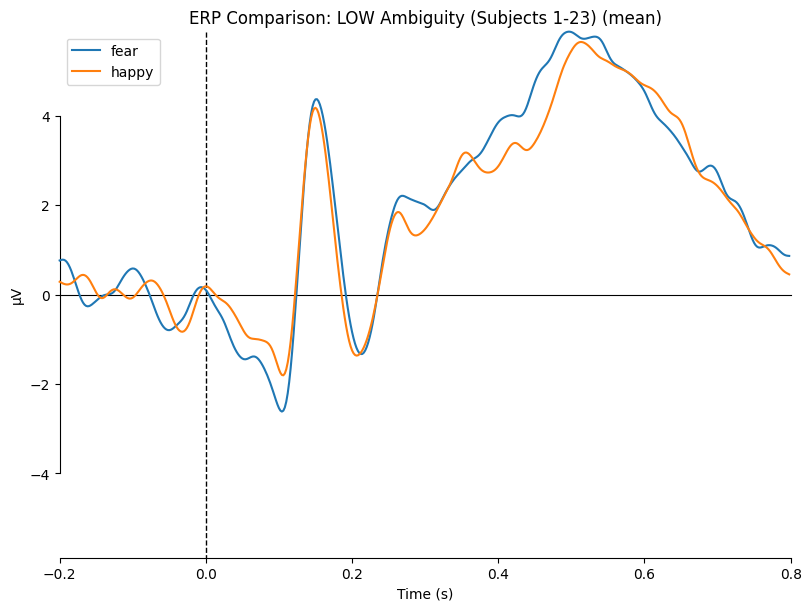

LOW: fear trials=22, happy trials=22
Identifying common channels ...
Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


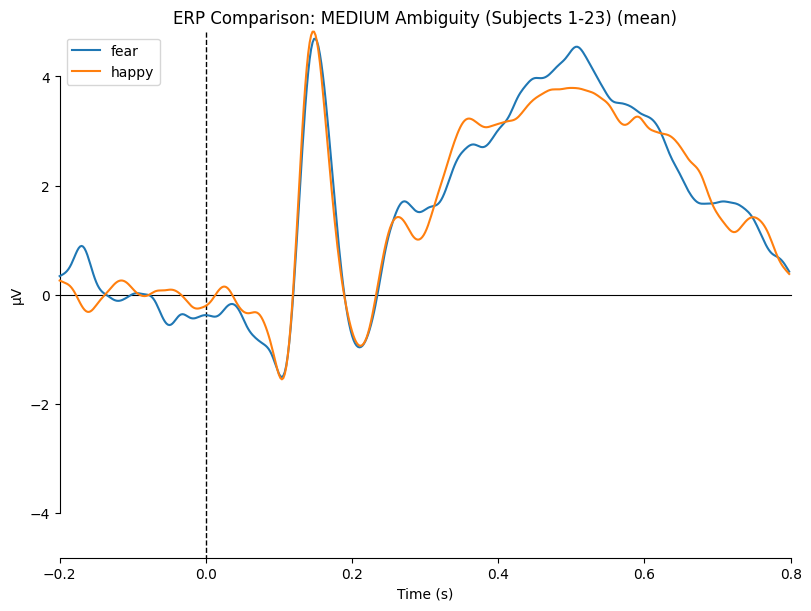

MEDIUM: fear trials=22, happy trials=22
Identifying common channels ...
Identifying common channels ...
combining channels using "mean"
combining channels using "mean"


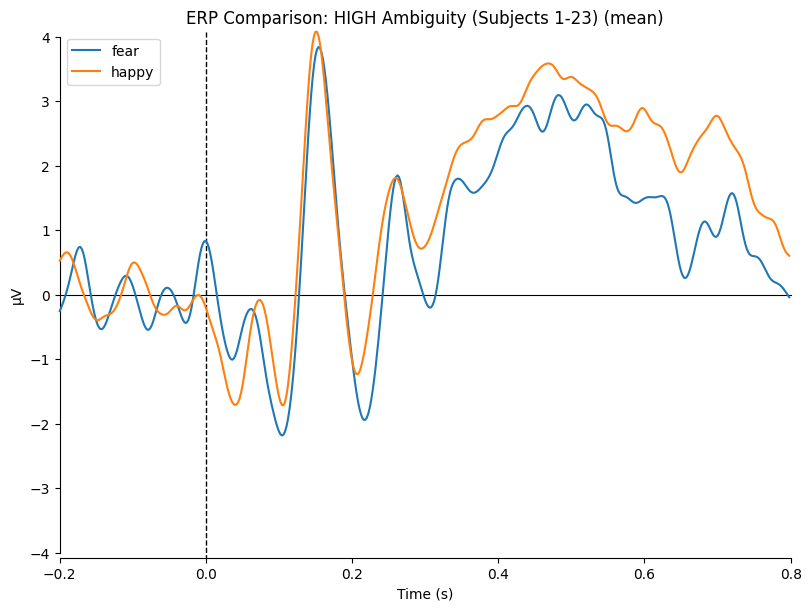

HIGH: fear trials=21, happy trials=22


In [ ]:
# Compare fear vs happy within each ambiguity level across all subjects

range_min = 1
range_max = 23
group_picks = ['CP3', 'CP4', 'PZ', 'CZ', 'CPZ']
subject_ids = range(range_min, range_max + 1)

def ambiguity_bin(code):
    if code in [1, 7]:
        return "low"
    elif code in [2, 3, 5, 6]:
        return "medium"
    elif code == 4:
        return "high"
    return "unknown"

# Storage for group evoked responses by ambiguity
group_evoked_by_ambiguity = {
    "low": {"fear": [], "happy": []},
    "medium": {"fear": [], "happy": []},
    "high": {"fear": [], "happy": []}
}

mat = sio.loadmat(behavior_mat_path, struct_as_record=False, squeeze_me=True)
eeg_data = mat["eegData"]

for sub_id in subject_ids:
    file = os.path.join(eeg_path, f"sub{sub_id}ar.set")
    if not os.path.exists(file):
        print(f"Subject {sub_id}: file not found, skipped")
        continue

    try:
        epochs_sub = mne.io.read_epochs_eeglab(file, verbose=False)
    except Exception as e:
        print(f"Subject {sub_id}: load failed ({e}), skipped")
        continue

    # Extract codes from EEG events
    event_codeI_sub, morph_levels_sub = _extract_codes_from_epochs(epochs_sub)

    # Load behavior data
    sub_beh = eeg_data[sub_id - 1]
    beh_codeI = np.asarray(sub_beh.codeI).astype(int)
    beh_codeL = np.asarray(sub_beh.codeL).astype(int)
    beh_vResp = np.asarray(sub_beh.vResp).astype(int)

    # Match EEG trials to behavior using (codeI, codeL) FIFO queue
    resp_queue = defaultdict(deque)
    for ci, cl, vr in zip(beh_codeI, beh_codeL, beh_vResp):
        resp_queue[(ci, cl)].append(vr)

    matched_vResp = []
    for ci, cl in zip(event_codeI_sub, morph_levels_sub):
        key = (int(ci), int(cl))
        if len(resp_queue[key]) == 0:
            matched_vResp.append(np.nan)
        else:
            matched_vResp.append(resp_queue[key].popleft())

    matched_vResp = np.asarray(matched_vResp, dtype=float)
    valid_mask = ~np.isnan(matched_vResp)

    if valid_mask.sum() == 0:
        print(f"Subject {sub_id}: no matched trials, skipped")
        continue

    # Keep only valid trials
    epochs_sub = epochs_sub[valid_mask]
    morph_levels_sub = morph_levels_sub[valid_mask]
    matched_vResp = matched_vResp[valid_mask].astype(int)

    # Convert response to label: 0=happy, 1=fear
    y_sub = np.zeros(len(matched_vResp), dtype=int)
    y_sub[matched_vResp == 2] = 1

    # Determine ambiguity level for each trial
    ambiguity_sub = np.array([ambiguity_bin(c) for c in morph_levels_sub])

    # Preprocess
    epochs_sub = epochs_sub.copy().filter(
        l_freq=0.1,
        h_freq=40.,
        method='iir',
        iir_params={'order': 4, 'ftype': 'butter'},
        verbose=False
    )
    epochs_sub.apply_baseline((-0.2, 0), verbose=False)
    epochs_sub = epochs_sub.copy().pick(group_picks, verbose=False)

    # For each ambiguity level, compute evoked responses for fear and happy
    for ambiguity_level in ["low", "medium", "high"]:
        level_mask = ambiguity_sub == ambiguity_level
        fear_mask = (y_sub == 1) & level_mask
        happy_mask = (y_sub == 0) & level_mask

        if fear_mask.sum() > 0:
            evoked_fear = epochs_sub[fear_mask].average()
            group_evoked_by_ambiguity[ambiguity_level]["fear"].append(evoked_fear)

        if happy_mask.sum() > 0:
            evoked_happy = epochs_sub[happy_mask].average()
            group_evoked_by_ambiguity[ambiguity_level]["happy"].append(evoked_happy)

    print(f"Subject {sub_id}: processed")

# Grand average for each ambiguity level and plot

for ambiguity_level in ["low", "medium", "high"]:
    fear_list = group_evoked_by_ambiguity[ambiguity_level]["fear"]
    happy_list = group_evoked_by_ambiguity[ambiguity_level]["happy"]

    if len(fear_list) > 0 and len(happy_list) > 0:
        group_fear = mne.grand_average(fear_list)
        group_happy = mne.grand_average(happy_list)

        mne.viz.plot_compare_evokeds(
            {"fear": group_fear, "happy": group_happy},
            picks=group_picks,
            combine='mean',
            title=f"ERP Comparison: {ambiguity_level.upper()} Ambiguity (Subjects {range_min}-{range_max})"
        )
        print(f"{ambiguity_level.upper()}: fear trials={len(fear_list)}, happy trials={len(happy_list)}")
    else:
        print(f"{ambiguity_level.upper()}: insufficient data (fear={len(fear_list)}, happy={len(happy_list)})")

# Baseline

In [35]:
epochs_lpp = epochs.copy().crop(tmin=0.4, tmax=0.7)

X = epochs_lpp.get_data().mean(axis=2)   # trials × channels

# Standardize features
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [36]:
def within_ambiguity(X, y, ambiguity, level):

    mask = ambiguity == level

    X_sub = X[mask]
    y_sub = y[mask]

    # Skip if only one class is present in this ambiguity bin
    if len(np.unique(y_sub)) < 2 or len(y_sub) < 10:
        return np.nan

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = []

    for train, test in cv.split(X_sub, y_sub):

        model = LogisticRegression(max_iter=1000)
        model.fit(X_sub[train], y_sub[train])

        preds = model.predict(X_sub[test])
        acc = balanced_accuracy_score(y_sub[test], preds)

        scores.append(acc)

    return np.mean(scores)

for level in ["low", "medium", "high"]:
    acc = within_ambiguity(X, y, ambiguity, level)
    print(level, acc)

low 0.5266666666666666
medium 0.5303496503496504
high 0.4583333333333333


### Cross decoding

In [37]:
def cross_ambiguity(X, y, ambiguity, train_level, test_level):

    train_mask = ambiguity == train_level
    test_mask = ambiguity == test_level

    X_train = X[train_mask]
    y_train = y[train_mask]
    X_test = X[test_mask]
    y_test = y[test_mask]

    # Need both classes in training and test to compute meaningful balanced accuracy
    if len(np.unique(y_train)) < 2 or len(np.unique(y_test)) < 2:
        return np.nan

    model = LogisticRegression(max_iter=1000)

    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    return balanced_accuracy_score(y_test, preds)

In [38]:
levels = ["low", "medium", "high"]

for train_level in levels:
    for test_level in levels:
        if train_level == test_level:
            continue
        score = cross_ambiguity(X, y, ambiguity, train_level, test_level)
        print(f"{train_level.capitalize()} → {test_level.capitalize()}: {score:.4f}")

Low → Medium: 0.5101
Low → High: 0.5833
Medium → Low: 0.4914
Medium → High: 0.6111
High → Low: 0.5580
High → Medium: 0.6087


# Advance

## Improved Feature Extraction

**Feature Groups:**

1. **Electrode-specific ERP features (11 features)**
   - P1 (85-115 ms): P7, P8 → 2 features
   - N170 (140-190 ms): P7, P8, TP7, TP8 → 4 features
   - EPN (250-350 ms): P7, P8 → 2 features
   - LPP (400-600 ms): CPZ, CZ, PZ → 3 features

2. **Spectral features (5 features)**
   - Alpha power (8-12 Hz @ N170 window): P7, P8 → 2 features
   - Theta power (4-7 Hz @ LPP window): CPZ, CZ, PZ → 3 features

3. **Spatial-temporal patterns (~200 features) (drop)**
   - N170 raw pattern (140-190 ms): 4 channels × timepoints
   - LPP raw pattern (400-600 ms): 3 channels × timepoints

**Total: ~216 features per trial**

**Classifier: Linear SVM with balanced class weights**


In [113]:
def extract_electrode_erp_features(epochs):
    """
    Extract electrode-specific ERP amplitude features.
    Returns 11 features total: P1(2) + N170(4) + EPN(2) + LPP(3)
    """
    features = []
    
    # P1: 85-115 ms, P7 P8 (2 features)
    p1 = epochs.copy().crop(tmin=0.085, tmax=0.115).pick(['P7', 'P8'])
    p1_data = p1.get_data().mean(axis=2)  # trials × 2
    features.append(p1_data)
    
    # N170: 140-190 ms, P7 P8 TP7 TP8 (4 features)
    n170 = epochs.copy().crop(tmin=0.140, tmax=0.190).pick(['P7', 'P8', 'TP7', 'TP8'])
    n170_data = n170.get_data().mean(axis=2)  # trials × 4
    features.append(n170_data)
    
    # EPN: 250-350 ms, P7 P8 (2 features)
    epn = epochs.copy().crop(tmin=0.250, tmax=0.350).pick(['P7', 'P8'])
    epn_data = epn.get_data().mean(axis=2)  # trials × 2
    features.append(epn_data)
    
    # LPP: 400-600 ms, CPZ CZ PZ (3 features)
    lpp = epochs.copy().crop(tmin=0.400, tmax=0.600).pick(['CPZ', 'CZ', 'PZ'])
    lpp_data = lpp.get_data().mean(axis=2)  # trials × 3
    features.append(lpp_data)
    
    result = np.hstack(features)  # trials × 11
    
    # Check for NaN values
    if np.isnan(result).any():
        nan_count = np.isnan(result).sum()
        print(f"WARNING: {nan_count} NaN values found in ERP features")
    
    return result


def extract_spectral_features(epochs):
    """
    Extract band power features: alpha during N170, theta during LPP.
    Returns 5 features total: alpha(2) + theta(3)
    """
    features = []
    sfreq = epochs.info['sfreq']
    
    # Alpha power (8-12 Hz) during N170 window (140-190 ms), P7 P8
    alpha_window = epochs.copy().crop(tmin=0.140, tmax=0.190).pick(['P7', 'P8'])
    alpha_data = alpha_window.get_data()  # trials × 2 × timepoints
    
    # Compute FFT and extract alpha band power
    alpha_power = []
    for trial in alpha_data:
        trial_power = []
        for ch in range(trial.shape[0]):
            # Use Welch's method with appropriate parameters
            n_samples = len(trial[ch])
            if n_samples < 4:
                # Too few samples, use mean power as fallback
                trial_power.append(0.0)
            else:
                nperseg = min(n_samples, 64)
                freqs_psd, psd = welch(trial[ch], fs=sfreq, nperseg=nperseg)
                alpha_band = (freqs_psd >= 8) & (freqs_psd <= 12)
                if alpha_band.sum() > 0:
                    power_val = psd[alpha_band].mean()
                    # Handle potential NaN from Welch
                    trial_power.append(power_val if np.isfinite(power_val) else 0.0)
                else:
                    trial_power.append(0.0)
        alpha_power.append(trial_power)
    features.append(np.array(alpha_power))  # trials × 2
    
    # Theta power (4-7 Hz) during LPP window (400-600 ms), CPZ CZ PZ
    theta_window = epochs.copy().crop(tmin=0.400, tmax=0.600).pick(['CPZ', 'CZ', 'PZ'])
    theta_data = theta_window.get_data()  # trials × 3 × timepoints
    
    theta_power = []
    for trial in theta_data:
        trial_power = []
        for ch in range(trial.shape[0]):
            n_samples = len(trial[ch])
            if n_samples < 4:
                trial_power.append(0.0)
            else:
                nperseg = min(n_samples, 128)
                freqs_psd, psd = welch(trial[ch], fs=sfreq, nperseg=nperseg)
                theta_band = (freqs_psd >= 4) & (freqs_psd <= 7)
                if theta_band.sum() > 0:
                    power_val = psd[theta_band].mean()
                    trial_power.append(power_val if np.isfinite(power_val) else 0.0)
                else:
                    trial_power.append(0.0)
        theta_power.append(trial_power)
    features.append(np.array(theta_power))  # trials × 3
    
    result = np.hstack(features)  # trials × 5
    
    # Check for NaN values
    if np.isnan(result).any():
        nan_count = np.isnan(result).sum()
        print(f"WARNING: {nan_count} NaN values found in spectral features")
    
    return result


def extract_spatial_temporal_features(epochs):
    """
    Extract raw spatial-temporal patterns from critical windows.
    N170 window: P7 P8 TP7 TP8 @ 140-190 ms
    LPP window: CPZ CZ PZ @ 400-600 ms
    """
    features = []
    
    # N170 spatial pattern: 4 channels × timepoints
    n170 = epochs.copy().crop(tmin=0.140, tmax=0.190).pick(['P7', 'P8', 'TP7', 'TP8'])
    n170_data = n170.get_data()  # trials × 4 × timepoints
    # Flatten channels and time
    n170_flat = n170_data.reshape(n170_data.shape[0], -1)  # trials × (4 * timepoints)
    features.append(n170_flat)
    
    # LPP spatial pattern: 3 channels × timepoints
    lpp = epochs.copy().crop(tmin=0.400, tmax=0.600).pick(['CPZ', 'CZ', 'PZ'])
    lpp_data = lpp.get_data()  # trials × 3 × timepoints
    # Flatten channels and time
    lpp_flat = lpp_data.reshape(lpp_data.shape[0], -1)  # trials × (3 * timepoints)
    features.append(lpp_flat)
    
    result = np.hstack(features)  # trials × ~200
    
    # Check for NaN values
    if np.isnan(result).any():
        nan_count = np.isnan(result).sum()
        print(f"WARNING: {nan_count} NaN values found in spatial-temporal features")
    
    return result


# def extract_all_features(epochs):
#     """
#     Combine all feature types: ERP + Spectral + Spatial-temporal.
#     Total ~216 features per trial.
#     """
#     erp_features = extract_electrode_erp_features(epochs)
#     spectral_features = extract_spectral_features(epochs)
#     spatial_features = extract_spatial_temporal_features(epochs)
    
#     all_features = np.hstack([erp_features, spectral_features, spatial_features])
    
#     # Final NaN check
#     nan_mask = np.isnan(all_features)
#     if nan_mask.any():
#         print(f"ERROR: {nan_mask.sum()} NaN values in final feature matrix!")
#         print(f"  Affected trials: {np.where(nan_mask.any(axis=1))[0]}")
#         print(f"  Affected features: {np.where(nan_mask.any(axis=0))[0]}")
#         # Replace NaN with 0 as fallback
#         all_features = np.nan_to_num(all_features, nan=0.0)
#         print("  NaN values replaced with 0")
#     else:
#         print(f"Feature dimensions: ERP={erp_features.shape[1]}, "
#               f"Spectral={spectral_features.shape[1]}, "
#               f"Spatial={spatial_features.shape[1]}, "
#               f"Total={all_features.shape[1]} - No NaN values ✓")
    
#     return all_features

def extract_all_features(epochs):
    """
    Combine all feature types: ERP + Spectral + Spatial-temporal.
    Total ~216 features per trial.
    """
    erp_features = extract_electrode_erp_features(epochs)
    spectral_features = extract_spectral_features(epochs)
    
    all_features = np.hstack([erp_features, spectral_features])
    
    # Final NaN check
    nan_mask = np.isnan(all_features)
    if nan_mask.any():
        print(f"ERROR: {nan_mask.sum()} NaN values in final feature matrix!")
        print(f"  Affected trials: {np.where(nan_mask.any(axis=1))[0]}")
        print(f"  Affected features: {np.where(nan_mask.any(axis=0))[0]}")
        # Replace NaN with 0 as fallback
        all_features = np.nan_to_num(all_features, nan=0.0)
        print("  NaN values replaced with 0")
    else:
        print(f"Feature dimensions: ERP={erp_features.shape[1]}, "
              f"Spectral={spectral_features.shape[1]}, "
              f"Total={all_features.shape[1]} - No NaN values ✓")
    
    return all_features


### Test feature extraction on single subject
Verify feature dimensions before processing all subjects

In [114]:
# Test on the already loaded epochs from subject 1
test_epochs = epochs.copy().filter(0.1, 30., verbose=False)
test_epochs.apply_baseline((-0.2, 0), verbose=False)

print(f"Testing feature extraction on {len(test_epochs)} trials...")
test_features = extract_all_features(test_epochs)
print(f"Output shape: {test_features.shape} (trials × features)")


/var/folders/bj/p5l9vvcj21nfh__sngfwhp3h0000gn/T/ipykernel_31040/4106743972.py:2: RuntimeWarning: filter_length (16501) is longer than the signal (500), distortion is likely. Reduce filter length or filter a longer signal.
  test_epochs = epochs.copy().filter(0.1, 30., verbose=False)


Testing feature extraction on 154 trials...
Feature dimensions: ERP=11, Spectral=5, Total=16 - No NaN values ✓
Output shape: (154, 16) (trials × features)


### Build dataset across all subjects
This loops through all subjects

In [115]:
all_X = []
all_y = []
all_ambiguity = []
all_subjects = []

for sub_id in range(1, 24):

    print(f"Processing subject {sub_id}")

    file = os.path.join(eeg_path, f"sub{sub_id}ar.set")
    if not os.path.exists(file):
        continue

    epochs = mne.io.read_epochs_eeglab(file, verbose=False)

    # Parse morph levels
    inv_event_id = {v: k for k, v in epochs.event_id.items()}
    events = epochs.events[:,2]
    event_names = [inv_event_id[e] for e in events]

    event_codeI = []
    morph_levels = []

    for name in event_names:
        m = re.search(r"\((\d+)(\d)\)", name)
        event_codeI.append(int(m.group(1)))
        morph_levels.append(int(m.group(2)))

    event_codeI = np.array(event_codeI)
    morph_levels = np.array(morph_levels)

    # Load behavior
    sub_beh = eeg_data[sub_id-1]

    beh_codeI = np.asarray(sub_beh.codeI).astype(int)
    beh_codeL = np.asarray(sub_beh.codeL).astype(int)
    beh_vResp = np.asarray(sub_beh.vResp).astype(int)

    resp_queue = defaultdict(deque)

    for ci,cl,vr in zip(beh_codeI,beh_codeL,beh_vResp):
        resp_queue[(ci,cl)].append(vr)

    matched_vResp = []

    for ci,cl in zip(event_codeI,morph_levels):
        key=(ci,cl)
        if len(resp_queue[key])==0:
            matched_vResp.append(np.nan)
        else:
            matched_vResp.append(resp_queue[key].popleft())

    matched_vResp = np.array(matched_vResp)

    valid_mask = ~np.isnan(matched_vResp)

    epochs = epochs[valid_mask]
    morph_levels = morph_levels[valid_mask]
    matched_vResp = matched_vResp[valid_mask].astype(int)

    # Labels: 1=fear (vResp==2), 0=happy (vResp==1)
    y = np.zeros(len(matched_vResp),dtype=int)
    y[matched_vResp==2] = 1

    def ambiguity_bin(code):
        if code in [1,7]:
            return "low"
        elif code in [2,3,5,6]:
            return "medium"
        elif code==4:
            return "high"

    ambiguity = np.array([ambiguity_bin(c) for c in morph_levels])

    # Preprocessing
    epochs = epochs.filter(0.1, 30., verbose=False)
    epochs.apply_baseline((-0.2, 0), verbose=False)

    # Extract all features (ERP + Spectral + Spatial-temporal)
    X = extract_all_features(epochs)

    all_X.append(X)
    all_y.append(y)
    all_ambiguity.append(ambiguity)
    all_subjects.append(np.full(len(y), sub_id))


Processing subject 1


/var/folders/bj/p5l9vvcj21nfh__sngfwhp3h0000gn/T/ipykernel_31040/1869227758.py:76: RuntimeWarning: filter_length (16501) is longer than the signal (500), distortion is likely. Reduce filter length or filter a longer signal.
  epochs = epochs.filter(0.1, 30., verbose=False)


Feature dimensions: ERP=11, Spectral=5, Total=16 - No NaN values ✓
Processing subject 2


/var/folders/bj/p5l9vvcj21nfh__sngfwhp3h0000gn/T/ipykernel_31040/1869227758.py:76: RuntimeWarning: filter_length (16501) is longer than the signal (500), distortion is likely. Reduce filter length or filter a longer signal.
  epochs = epochs.filter(0.1, 30., verbose=False)


Feature dimensions: ERP=11, Spectral=5, Total=16 - No NaN values ✓
Processing subject 3


...

Feature dimensions: ERP=11, Spectral=5, Total=16 - No NaN values ✓
Processing subject 22


/var/folders/bj/p5l9vvcj21nfh__sngfwhp3h0000gn/T/ipykernel_31040/1869227758.py:76: RuntimeWarning: filter_length (16501) is longer than the signal (500), distortion is likely. Reduce filter length or filter a longer signal.
  epochs = epochs.filter(0.1, 30., verbose=False)


Feature dimensions: ERP=11, Spectral=5, Total=16 - No NaN values ✓
Processing subject 23


/var/folders/bj/p5l9vvcj21nfh__sngfwhp3h0000gn/T/ipykernel_31040/1869227758.py:76: RuntimeWarning: filter_length (16501) is longer than the signal (500), distortion is likely. Reduce filter length or filter a longer signal.
  epochs = epochs.filter(0.1, 30., verbose=False)


Feature dimensions: ERP=11, Spectral=5, Total=16 - No NaN values ✓


In [116]:
X = np.vstack(all_X)
y = np.concatenate(all_y)
ambiguity = np.concatenate(all_ambiguity)
subjects = np.concatenate(all_subjects)

print(X.shape)

(4275, 16)


### Check for data quality issues

In [117]:
# Check for NaN and infinite values
print("Data quality check:")
print(f"  Total samples: {X.shape[0]}")
print(f"  Total features: {X.shape[1]}")
print(f"  NaN values: {np.isnan(X).sum()}")
print(f"  Infinite values: {np.isinf(X).sum()}")
print(f"  Label distribution: {np.bincount(y)}")

# If NaN exists, show details
if np.isnan(X).any():
    nan_rows = np.where(np.isnan(X).any(axis=1))[0]
    nan_cols = np.where(np.isnan(X).any(axis=0))[0]
    print(f"\n  WARNING: NaN detected!")
    print(f"  Affected samples: {len(nan_rows)} / {X.shape[0]}")
    print(f"  Affected features: {len(nan_cols)} / {X.shape[1]}")
    print(f"  Replacing NaN with 0...")
    X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)
    print(f"  After replacement - NaN: {np.isnan(X).sum()}, Inf: {np.isinf(X).sum()}")
else:
    print("\n  ✓ No NaN or Inf values detected")


Data quality check:
  Total samples: 4275
  Total features: 16
  NaN values: 0
  Infinite values: 0
  Label distribution: [2362 1913]

  ✓ No NaN or Inf values detected


### Subject-wise train test split

In [118]:
unique_subjects = np.unique(subjects)

train_sub, test_sub = train_test_split(
    unique_subjects,
    test_size=0.3,
    random_state=42
)

train_mask = np.isin(subjects, train_sub)
test_mask = np.isin(subjects, test_sub)

X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[test_mask]
y_test = y[test_mask]

ambiguity_test = ambiguity[test_mask]

### Train Linear SVM classifier

**Pipeline:**
1. StandardScaler (fit on training set only)
2. Linear SVM with balanced class weights

**Note:** Scaler is fitted on training data and applied to test data to prevent data leakage.

In [119]:
from sklearn.svm import LinearSVC

# Build pipeline with StandardScaler and Linear SVM
clf = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(
        class_weight="balanced",
        max_iter=2000,
        random_state=42,
        dual="auto"  # Use auto to select based on data
    ))
])

# Fit on training set only
clf.fit(X_train, y_train)

# Predict on test set
preds = clf.predict(X_test)

overall_acc = balanced_accuracy_score(y_test, preds)
print(f"Overall balanced accuracy: {overall_acc:.4f}")


Overall balanced accuracy: 0.5067


### Evaluate accuracy per ambiguity level

In [120]:
levels = ["low","medium","high"]

for level in levels:

    mask = ambiguity_test == level

    if np.sum(mask) == 0:
        continue

    acc = balanced_accuracy_score(
        y_test[mask],
        preds[mask]
    )

    print(f"{level} ambiguity accuracy: {acc:.3f}")

low ambiguity accuracy: 0.520
medium ambiguity accuracy: 0.515
high ambiguity accuracy: 0.435


### Analyze feature importance

Average absolute coefficient magnitude by feature group:
  ERP features:              0.0584
  Spectral features:         0.0214


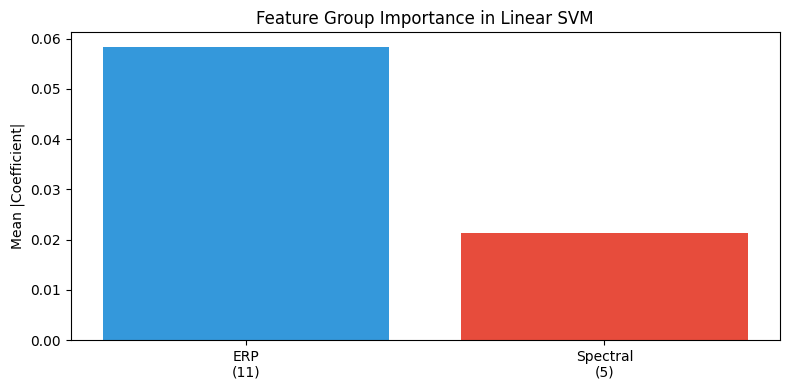

In [121]:
# Extract SVM coefficients
svm_coefs = np.abs(clf.named_steps['svm'].coef_[0])

# Feature group boundaries (adjust based on actual dimensions)
# ERP: first 11 features
# Spectral: next 5 features
# Spatial: remaining features

n_erp = 11
n_spectral = 5
# n_spatial = len(svm_coefs) - n_erp - n_spectral

erp_importance = svm_coefs[:n_erp].mean()
spectral_importance = svm_coefs[n_erp:n_erp+n_spectral].mean()
# spatial_importance = svm_coefs[n_erp+n_spectral:].mean()

print("Average absolute coefficient magnitude by feature group:")
print(f"  ERP features:              {erp_importance:.4f}")
print(f"  Spectral features:         {spectral_importance:.4f}")
# print(f"  Spatial-temporal features: {spatial_importance:.4f}")

# Visualize
plt.figure(figsize=(8, 4))
# plt.bar(['ERP\n(11)', 'Spectral\n(5)', f'Spatial-temporal\n({n_spatial})'], 
#         [erp_importance, spectral_importance, spatial_importance],
#         color=['#3498db', '#e74c3c', '#2ecc71'])
plt.bar(['ERP\n(11)', 'Spectral\n(5)'],
        [erp_importance, spectral_importance],
        color=['#3498db', '#e74c3c'])
plt.ylabel('Mean |Coefficient|')
plt.title('Feature Group Importance in Linear SVM')
plt.tight_layout()
plt.show()
